Imports and data loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    RocCurveDisplay
)

In [2]:
df = pd.read_csv("classification_escalation.csv")
print(df.shape)
display(df.head())
print(df.info())
print(df["escalated"].value_counts(normalize=True).rename("proportion"))

(900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0


<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB
None
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64


count missing values

In [3]:
df.isna().sum()

complexity_score           0
team_experience_years     31
priority                  18
channel                    0
customer_tenure_months    22
escalated                  0
dtype: int64

### Step 1 – Findings

- **Shape:** The dataset has 900 rows (tickets) and 6 columns: 5 predictors and the target `escalated`.
- **Types:** `complexity_score` (integer), `team_experience_years` and `customer_tenure_months` (float) are numeric. `priority` (low/medium/high) and `channel` (email/web/phone) are categorical. `escalated` is a binary 0/1 integer target.
- **Missing values:** Missing values appear in `team_experience_years` (31), `priority` (18) and `customer_tenure_months` (22). The other columns are complete. These will be handled inside the preprocessing pipeline (median imputation for numeric, most-frequent for categorical).
- **Target prevalence:** 186 of 900 tickets (about 20.7%) were escalated and 714 (about 79.3%) were not. The classes are imbalanced, so accuracy alone will be misleading, because a model that never escalates would already score about 79%.

## Step 2 – Problem framing and train/test split

**Why classification?** The target `escalated` takes only two values (1 = escalated, 0 = not escalated), so we predict a discrete category rather than a continuous quantity. This makes it a binary classification problem.

**Positive class:** `escalated = 1`. Precision and recall are defined with respect to this class: recall is the share of truly escalating tickets we catch, and precision is the share of our escalation flags that are correct. We choose it as positive because missing an escalation (a false negative) is the costly error.

In [4]:
X = df.drop(columns="escalated")
y = df["escalated"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train class counts:\n", y_train.value_counts())
print("Test class counts:\n", y_test.value_counts())
print("Train prevalence:", round(y_train.mean(), 4), "| Test prevalence:", round(y_test.mean(), 4))

Train: (675, 5) Test: (225, 5)
Train class counts:
 escalated
0    535
1    140
Name: count, dtype: int64
Test class counts:
 escalated
0    179
1     46
Name: count, dtype: int64
Train prevalence: 0.2074 | Test prevalence: 0.2044


**Why stratify?** The positive class is only about 21% of the data. Stratifying keeps that proportion nearly identical in train and test, so the test metrics are comparable and the test set contains enough positives (46) to evaluate recall and precision. The test set is held out and only used for final evaluation, not for fitting or imputing.

## Step 3 – Preprocessing

- **Numeric** (`complexity_score`, `team_experience_years`, `customer_tenure_months`): impute missing values with the **median** (robust to outliers), then **standardize** (zero mean, unit variance). Scaling matters for k-NN (distance-based) and helps logistic regression.
- **Categorical** (`priority`, `channel`): impute missing values with the **most frequent** category, then **one-hot encode**.
- Everything is wrapped in a `ColumnTransformer` that will sit inside each model's `Pipeline`. The imputers, scaler and encoder are therefore fit on training data only, which prevents leakage from the test set (and from the validation folds during cross-validation).

In [5]:
num_cols = ["complexity_score", "team_experience_years", "customer_tenure_months"]
cat_cols = ["priority", "channel"]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocess = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols),
])

In [6]:
Xt = preprocess.fit_transform(X_train)
print("Transformed train shape:", Xt.shape)
print(list(preprocess.get_feature_names_out()))
print("Median imputation values:", preprocess.named_transformers_["num"]["imputer"].statistics_.round(2))
print("Most-frequent values:", preprocess.named_transformers_["cat"]["imputer"].statistics_)

Transformed train shape: (675, 9)
['num__complexity_score', 'num__team_experience_years', 'num__customer_tenure_months', 'cat__priority_high', 'cat__priority_low', 'cat__priority_medium', 'cat__channel_email', 'cat__channel_phone', 'cat__channel_web']
Median imputation values: [ 5.   4.4 19. ]
Most-frequent values: ['low' 'email']


## Step 4 – Models and comparison

Four classifiers, each wrapped in a `Pipeline` (preprocessing + model) so preprocessing is fit on the training data only:
1. Majority-class baseline (always predicts "not escalated")
2. Logistic regression
3. Linear Discriminant Analysis (LDA)
4. k-NN with k = 15

Predictions use the default 0.5 probability cutoff. ROC-AUC uses the predicted probability of class 1.

In [7]:
models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=1000),
    "LDA": LinearDiscriminantAnalysis(),
    "k-NN (k=15)": KNeighborsClassifier(n_neighbors=15),
}

fitted = {}
rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_prob),
    })

results = pd.DataFrame(rows).set_index("model").round(3)
results

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Majority baseline,0.796,0.00,0.000,0.000,0.500
Logistic regression,0.822,0.75,0.196,0.310,0.811
LDA,0.822,0.75,0.196,0.310,0.809
k-NN (k=15),0.796,0.50,0.087,0.148,0.705


### Observations (Step 4)

- **Accuracy is misleading:** the do-nothing baseline scores 0.796 accuracy while catching zero escalations (recall 0). The real models only reach about 0.82, a small gain on this measure.
- **Strongest recall:** logistic regression and LDA tie at 0.196. Even they miss about 80% of escalated tickets at the default 0.5 cutoff.
- **Strongest precision and F1:** logistic regression and LDA tie again (precision 0.75, F1 0.31). They also have the best ROC-AUC (about 0.81), so they rank tickets reasonably well.
- **k-NN (k=15)** is the weakest (recall 0.087, F1 0.148, AUC 0.705).
- All models are conservative at 0.5, so the threshold analysis in the next steps matters.

[[176   3]
 [ 37   9]]


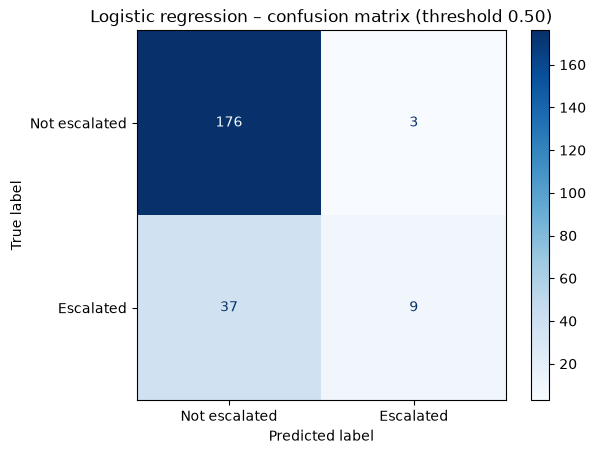

               precision    recall  f1-score   support

Not escalated       0.83      0.98      0.90       179
    Escalated       0.75      0.20      0.31        46

     accuracy                           0.82       225
    macro avg       0.79      0.59      0.60       225
 weighted avg       0.81      0.82      0.78       225



In [8]:
lr = fitted["Logistic regression"]
y_pred_lr = lr.predict(X_test)
y_prob_lr = lr.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred_lr)
print(cm)

ConfusionMatrixDisplay(cm, display_labels=["Not escalated", "Escalated"]).plot(cmap="Blues")
plt.title("Logistic regression – confusion matrix (threshold 0.50)")
plt.show()

print(classification_report(y_test, y_pred_lr, target_names=["Not escalated", "Escalated"]))

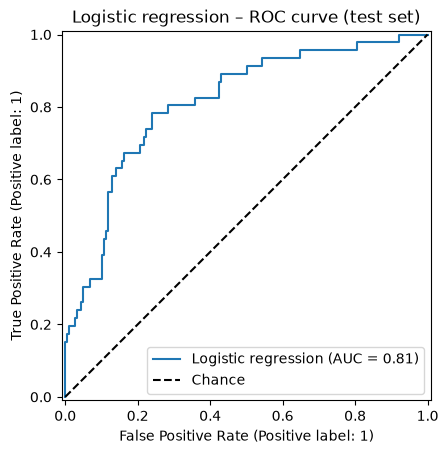

ROC-AUC: 0.811


In [9]:
RocCurveDisplay.from_predictions(y_test, y_prob_lr, name="Logistic regression")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.title("Logistic regression – ROC curve (test set)")
plt.legend()
plt.show()

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_lr), 3))

### Observations (Step 5)

- At the default 0.50 threshold the model makes only 3 false positives but 37 false negatives: it almost never flags a ticket unless it is very sure, so most escalations are missed.
- The ROC curve (AUC ≈ 0.81) shows the model *does* separate escalated from non-escalated tickets well above chance. The weak recall comes from the cutoff, not from a lack of signal, which is why threshold selection (next step) can help.
- ROC-AUC is threshold-independent: it measures ranking quality across all cutoffs.

## Step 6 – Threshold analysis and cost

Instead of the default 0.50 cutoff, we classify a ticket as "escalate" when P(escalated | x) ≥ t for t in {0.20, 0.30, 0.40, 0.50, 0.60, 0.70}, using the logistic regression probabilities on the test set.

Illustrative cost: **cost = 5 × FN + 1 × FP**. A missed escalation (FN) is assumed five times as costly as an unnecessary escalation (FP).

In [10]:
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
rows = []
for t in thresholds:
    y_pred_t = (y_prob_lr >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()
    rows.append({
        "threshold": t,
        "precision": precision_score(y_test, y_pred_t, zero_division=0),
        "recall": recall_score(y_test, y_pred_t),
        "f1": f1_score(y_test, y_pred_t),
        "FP": fp,
        "FN": fn,
        "cost (5*FN + FP)": 5 * fn + fp,
    })

threshold_table = pd.DataFrame(rows).set_index("threshold").round(3)
threshold_table

,precision,recall,f1,FP,FN,cost (5*FN + FP)
threshold,,,,,,
0.2,0.429,0.783,0.554,48,10,98
0.3,0.549,0.609,0.577,23,18,113
0.4,0.571,0.261,0.358,9,34,179
0.5,0.750,0.196,0.310,3,37,188
0.6,1.000,0.065,0.122,0,43,215
0.7,0.000,0.000,0.000,0,46,230


In [11]:
best_t = threshold_table["cost (5*FN + FP)"].idxmin()
print("Cost-minimizing threshold:", best_t)
print(threshold_table.loc[best_t])

# Worked example for t = 0.20: FN = 10, FP = 48
print("Cost at 0.20 =", 5 * 10 + 1 * 48)

Cost-minimizing threshold: 0.2
precision            0.429
recall               0.783
f1                   0.554
FP                  48.000
FN                  10.000
cost (5*FN + FP)    98.000
Name: 0.2, dtype: float64
Cost at 0.20 = 98


### Observations (Step 6)

- **Lowering the threshold** makes the model flag more tickets: recall rises (0.065 at 0.60 → 0.783 at 0.20) and FN falls, but FP rises (0 → 48) and precision drops (1.00 → 0.43). It is a trade-off, not a free improvement.
- **Cost-minimizing threshold: 0.20**, with cost 5×10 + 48 = 98, versus 188 at the default 0.50. Because a missed escalation is 5× as costly, accepting more false alarms pays off.
- **F1 is highest at 0.30** (0.577), so F1 and the cost function pick different thresholds. F1 treats FP and FN equally, while our cost function does not.
- **Optimism caveat:** I chose the threshold by looking at the same test set I evaluate on. If we keep trying thresholds, models and settings against this one test set, we start fitting to its noise, and the 98 will be an optimistic estimate. With only 46 positives in the test set, a change of a few tickets moves the numbers a lot. The threshold should be chosen on validation data or via cross-validation, then confirmed once on fresh data.

## Step 7 – Stratified 5-fold CV to tune k-NN

On the **training set only**, I use stratified 5-fold cross-validation to compare k = 5, 9, 15, 21, 31, scored by F1 (the positive class is rare, and F1 balances precision and recall). Preprocessing sits inside the pipeline, so it is re-fit within each fold and there is no leakage.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

knn_pipe = Pipeline([("prep", preprocess), ("model", KNeighborsClassifier())])
grid = GridSearchCV(
    knn_pipe,
    param_grid={"model__n_neighbors": [5, 9, 15, 21, 31]},
    scoring="f1",
    cv=cv,
)
grid.fit(X_train, y_train)

cv_results = pd.DataFrame(grid.cv_results_)[
    ["param_model__n_neighbors", "mean_test_score", "std_test_score", "rank_test_score"]
].round(3)
display(cv_results)
print("Best params:", grid.best_params_, "| best CV F1:", round(grid.best_score_, 3))

,param_model__n_neighbors,mean_test_score,std_test_score,rank_test_score
0,5,0.243,0.095,1
1,9,0.198,0.065,2
2,15,0.160,0.065,3
3,21,0.146,0.056,4
4,31,0.112,0.040,5


Best params: {'model__n_neighbors': 5} | best CV F1: 0.243


In [13]:
best_knn = grid.best_estimator_
yp = best_knn.predict(X_test)
yprob = best_knn.predict_proba(X_test)[:, 1]
print("Tuned k-NN test -> acc %.3f prec %.3f rec %.3f f1 %.3f auc %.3f" % (
    accuracy_score(y_test, yp), precision_score(y_test, yp, zero_division=0),
    recall_score(y_test, yp), f1_score(y_test, yp), roc_auc_score(y_test, yprob)))

Tuned k-NN test -> acc 0.791 prec 0.462 rec 0.130 f1 0.203 auc 0.631


### Observations (Step 7)

- F1 falls steadily as k grows. Larger k smooths predictions toward the majority class (not escalated), so fewer positives are flagged.
- The best k is 5, but CV F1 (0.243) is low and the standard deviation across folds (about 0.10) is large, so the choice of k is not very stable.
- Tuned k-NN is still the weakest model on the test set (AUC 0.63), well below logistic regression (0.81).

## Step 8 – Prior, likelihood, posterior, evidence

Bayes' rule: P(escalated | x) = P(x | escalated) · P(escalated) / P(x)

- **Prior, P(escalated):** how likely any ticket is to escalate before looking at its features. In our data, about 0.207.
- **Likelihood, P(x | escalated):** how likely a ticket with these features (for example complexity 9, low-experience team, phone channel) is among tickets that *did* escalate. It is compared against P(x | not escalated).
- **Evidence, P(x):** how common this feature pattern is across *all* tickets: P(x | esc)·P(esc) + P(x | not esc)·P(not esc). It normalizes the result so the posteriors sum to 1.
- **Posterior, P(escalated | x):** the updated probability that this particular ticket escalates after seeing its features. This is what logistic regression and LDA estimate, and what we compare with a threshold.

Example: a high-complexity ticket handled by a junior team is more common among escalated tickets than among non-escalated ones, so the likelihood ratio is above 1 and the posterior rises above the 0.207 prior.

## Step 9 – Cost-sensitive decision (posterior = 0.30, C_FP = 1, C_FN = 5)

Let p = P(escalated | x).

- **Escalate:** wrong only if the ticket would not have escalated (probability 1 − p), costing C_FP.
  Expected cost = (1 − p) · 1 = 0.70 · 1 = **0.70**
- **Do not escalate:** wrong only if the ticket would have escalated (probability p), costing C_FN.
  Expected cost = p · 5 = 0.30 · 5 = **1.50**

Escalating is cheaper (0.70 < 1.50), so we escalate even though the ticket is more likely *not* to escalate.

**Derivation of the threshold.** Escalate when expected cost of escalating < expected cost of not escalating:

(1 − p) · C_FP < p · C_FN
C_FP − p·C_FP < p·C_FN
p > C_FP / (C_FP + C_FN) = 1 / (1 + 5) = **1/6 ≈ 0.167**

This lies close to the empirically best grid threshold (0.20) from Step 6. The grid has no 0.167, and 0.20 is the nearest value.

In [14]:
for name in ["Logistic regression", "LDA"]:
    model = models[name]
    s = cross_validate(Pipeline([("prep", preprocess), ("model", model)]),
                       X_train, y_train, cv=cv, scoring=["f1", "recall", "roc_auc"])
    print(name, {k.replace("test_", ""): round(v.mean(), 3) for k, v in s.items() if k.startswith("test")})

Logistic regression {'f1': np.float64(0.248), 'recall': np.float64(0.164), 'roc_auc': np.float64(0.744)}
LDA {'f1': np.float64(0.266), 'recall': np.float64(0.179), 'roc_auc': np.float64(0.743)}


## Recommendation

**Model choice.** I recommend logistic regression. It matches LDA on nearly every metric (test ROC-AUC about 0.81, versus 0.71 for k-NN with k=15), it is simple to explain to support staff, and its coefficients can be inspected. k-NN was the weakest model, and tuning k by 5-fold cross-validated F1 chose k=5, but it still reached only an F1 of 0.20 and an AUC of 0.63 on the test set, so I would not deploy it. Accuracy is a poor guide here: a baseline that never escalates scores 0.796, so the 0.82 of the real models is only a small gain.

**Threshold and error costs.** At the default 0.50 cutoff, logistic regression catches only 9 of 46 escalations (recall 0.196). Under the illustrative cost 5×FN + FP, a threshold of 0.20 minimizes cost on the test set (98, from 10 FN and 48 FP), compared with 188 at 0.50. This agrees with the decision-theory result: escalate whenever the posterior probability exceeds 1/6 (about 0.167), because 1/(1+5) is the break-even point. The cost of 5 is an assumption, and the threshold should be re-derived from real costs of missed escalations and wasted review time.

**Limitations.** The data are synthetic and small, with only 46 positives in the test set, so every metric is noisy. I chose the threshold using the same test set I report on, so the cost of 98 is probably optimistic. The threshold should be chosen with cross-validation or a separate validation set. Cross-validated AUC on the training data (about 0.74) was lower than the test AUC (0.81), which is another sign of how much the estimate varies. Missing values were imputed with medians and most-frequent categories, which may hide patterns in why data are missing.

**Responsible use.** At a 0.20 threshold more than half of the flagged tickets are false alarms (precision 0.43), which adds workload and may delay other customers. The model should support triage, not replace human judgment, and should not be used to penalize agents or customers. Before deployment I would check performance by channel, priority and customer tenure for uneven error rates, test calibration of the probabilities, validate on recent real tickets, monitor drift after launch, and record who is accountable when the model is wrong.

## Answers to the questions

1. **Why can accuracy mislead?** About 79% of tickets are not escalated, so a model that never escalates gets 0.796 accuracy while catching zero escalations.
2. **Strongest recall / precision / F1?** At 0.50, logistic regression and LDA tie for recall (0.196), precision (0.75) and F1 (0.31). k-NN (k=15) is weakest. Only the models, not the baseline, produce meaningful AUC (LR 0.811, LDA 0.809, k-NN 0.705).
3. **What changes when the threshold is lowered?** More tickets are flagged: recall rises, FN falls, FP rises, and precision generally falls.
4. **Which threshold minimizes 5×FN + FP?** 0.20 (cost 98). The estimate may be optimistic because the test set was used to pick the threshold, and repeated tuning on it fits its noise (only 46 positives).
5. **Bayes terms:** see Step 8.
6. **Expected costs and threshold:** escalating costs 0.70, not escalating costs 1.50, and the threshold is 1/6 ≈ 0.167 (Step 9).
7. **Which model to deploy?** Logistic regression with a lowered threshold (about 0.17–0.20), as a triage aid. It still needs validation on real recent data, probability calibration checks, subgroup error analysis (channel, priority, tenure), threshold selection by cross-validation or a validation set, drift monitoring, and a human in the loop.